Module importation

In [1]:
import os
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'


Download my first data from kagglehub ecommerce_event_history_in_electronic_store for the funnel analysis


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mkechinov/ecommerce-events-history-in-electronics-store")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\mkechinov\ecommerce-events-history-in-electronics-store\versions\1


Loading the Data

In [3]:
import glob
files = glob.glob(os.path.join(path, "*.csv"))
print(files)
df = pd.read_csv(files[0])

['C:\\Users\\USER\\.cache\\kagglehub\\datasets\\mkechinov\\ecommerce-events-history-in-electronics-store\\versions\\1\\events.csv']


Checking the Data Quality 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 885129 entries, 0 to 885128
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     885129 non-null  object 
 1   event_type     885129 non-null  object 
 2   product_id     885129 non-null  int64  
 3   category_id    885129 non-null  int64  
 4   category_code  648910 non-null  object 
 5   brand          672765 non-null  object 
 6   price          885129 non-null  float64
 7   user_id        885129 non-null  int64  
 8   user_session   884964 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 60.8+ MB


In [5]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df['event_time'].min(), df['event_time'].max())
print(df['event_type'].value_counts())

(885129, 9)
event_time        object
event_type        object
product_id         int64
category_id        int64
category_code     object
brand             object
price            float64
user_id            int64
user_session      object
dtype: object
event_time            0
event_type            0
product_id            0
category_id           0
category_code    236219
brand            212364
price                 0
user_id               0
user_session        165
dtype: int64
2020-09-24 11:57:06 UTC 2021-02-28 23:59:09 UTC
event_type
view        793748
cart         54035
purchase     37346
Name: count, dtype: int64


Cleaning Up Date from object to datetime
and checking data Quality in against nagative value

In [6]:
df['event_time'] = pd.to_datetime(df['event_time'])
print(df.duplicated().sum())
print(df['price'].describe())
print((df['price'] <= 0).sum())
print(df[df['user_session'].isnull()].head())

655
count    885129.000000
mean        146.328713
std         296.807683
min           0.220000
25%          26.460000
50%          65.710000
75%         190.490000
max       64771.060000
Name: price, dtype: float64
0
                     event_time event_type  product_id          category_id  \
2257  2020-09-24 23:47:04+00:00       view     1715896  2144415926731145430   
6872  2020-09-26 05:14:39+00:00       view     3791351  2144415926966026460   
7898  2020-09-26 10:58:24+00:00       view     1785245  2144415925011480748   
11782 2020-09-27 11:59:41+00:00       view     1153724  2144415921169498184   
24461 2020-09-30 07:31:01+00:00       view     1559260  2144415928845074703   

                              category_code  brand   price  \
2257   computers.components.network_adapter    NaN   17.40   
6872               computers.components.cpu    amd  204.29   
7898                    stationery.cartrige  canon   43.11   
11782                                   NaN    zte    6.29 

Droping duplicated value

In [7]:
df = df.drop_duplicates()
print(df.shape)

(884474, 9)


Filling my brand, category_code column missing value to unknown

In [8]:
df['brand'] = df['brand'].fillna('unknown')
df['category_code'] = df['category_code'].fillna('unknown')
print(df.isnull().sum())
print(df[df['price'] > 10000][['event_type','category_code','brand','price']].head(10))

event_time         0
event_type         0
product_id         0
category_id        0
category_code      0
brand              0
price              0
user_id            0
user_session     162
dtype: int64
       event_type                  category_code    brand     price
12777        view           electronics.video.tv       lg  12559.95
13638        view           electronics.video.tv  samsung  27775.87
20028        view           electronics.video.tv  samsung  27775.87
51272        view  computers.peripherals.monitor       lg  64771.06
63739        view  computers.peripherals.printer  unknown  26909.62
86316        view  computers.peripherals.monitor       lg  64771.06
119620       view  computers.peripherals.printer    xerox  11036.30
153263       view           electronics.video.tv       lg  12559.95
255595       view           electronics.video.tv       lg  10644.92
261247       view           electronics.video.tv     acer  11886.76


In [9]:
print(df[(df['price'] > 10000) & (df['event_type'] == 'purchase')].shape)

(0, 9)


In [10]:
df = df.dropna(subset=['user_session'])
print(df.shape)

# unique users at each funnel stage
funnel = df.groupby('event_type')['user_id'].nunique()
print(funnel)

(884312, 9)
event_type
cart         36948
purchase     21304
view        406817
Name: user_id, dtype: int64


Filltering buyers from carter

In [11]:
buyers = set(df[df['event_type']=='purchase']['user_id'])
carters = set(df[df['event_type']=='cart']['user_id'])
print(len(buyers - carters))

1249


In [12]:
viewers = set(df[df['event_type']=='view']['user_id'])
carters = set(df[df['event_type']=='cart']['user_id'])
buyers  = set(df[df['event_type']=='purchase']['user_id'])

print(len(carters - viewers))

2


In [13]:
step1 = viewers
step2 = step1 & carters
step3 = step2 & buyers
print(len(step1), len(step2), len(step3))

406817 36946 20053


Grouping each customer in to their event type
converting the group in to data frame and to show the pencentage of customers that view then cart then buy

In [14]:
df['main_category'] = df['category_code'].str.split('.').str[0]

views = df[df.event_type=='view'].groupby('main_category')['user_id'].nunique()
carts = df[df.event_type=='cart'].groupby('main_category')['user_id'].nunique()
buys  = df[df.event_type=='purchase'].groupby('main_category')['user_id'].nunique()

cat = pd.DataFrame({'viewers': views, 'carters': carts, 'buyers': buys}).fillna(0)
cat['view_to_cart_%'] = (cat.carters / cat.viewers * 100).round(1)
cat['cart_to_buy_%']  = (cat.buyers / cat.carters * 100).round(1)
cat.sort_values('viewers', ascending=False)

,viewers,carters,buyers,view_to_cart_%,cart_to_buy_%
main_category,,,,,
unknown,129885,8140,4779.0,6.3,58.7
computers,115515,17073,9423.0,14.8,55.2
electronics,89729,6981,4141.0,7.8,59.3
stationery,23208,2315,1559.0,10.0,67.3
appliances,22373,936,554.0,4.2,59.2
auto,17077,1133,628.0,6.6,55.4
construction,14969,1039,560.0,6.9,53.9
furniture,1902,128,75.0,6.7,58.6
country_yard,1647,39,18.0,2.4,46.2


In [15]:
mapping = (df[df['main_category'] != 'unknown']
           .drop_duplicates('product_id')
           .set_index('product_id')['main_category'])

df['main_category_fixed'] = df['main_category']
mask = df['main_category'] == 'unknown'
df.loc[mask, 'main_category_fixed'] = df.loc[mask, 'product_id'].map(mapping).fillna('unknown')

print((df['main_category'] == 'unknown').sum())
print((df['main_category_fixed'] == 'unknown').sum())

236001
236001


In [16]:
known = (df[df['category_code'] != 'unknown']
         .drop_duplicates('category_id')
         .set_index('category_id')['category_code'])

df['category_code_fixed'] = df['category_code']
mask = df['category_code'] == 'unknown'
df.loc[mask, 'category_code_fixed'] = df.loc[mask, 'category_id'].map(known).fillna('unknown')

print((df['category_code'] == 'unknown').sum())
print((df['category_code_fixed'] == 'unknown').sum())

236001
236001


In [17]:
t = df.groupby(['user_id', 'event_type'])['event_time'].min().unstack()
ok = t.dropna(subset=['view', 'cart', 'purchase'])
in_order = (ok['view'] <= ok['cart']) & (ok['cart'] <= ok['purchase'])
print(len(ok), in_order.sum())

20053 19921


In [18]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


Reading my seconed data which is in excel format E_commerce behaiour Data to analys for rfm

In [19]:
sheet = pd.read_excel('C:\\Users\\USER\\Desktop\\E_Commerce Behavior Data\\online_retail_II.xlsx', sheet_name=None, engine='openpyxl')  
print(sheet.keys())

rt = pd.concat(sheet.values(), ignore_index=True)
print (rt.head())
rt.info()


dict_keys(['Year 2009-2010', 'Year 2010-2011'])
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ---

In [20]:
print(rt['Invoice'].astype(str).str.startswith('C').sum())
print((rt['Quantity'] <= 0).sum(), (rt['Price'] <= 0).sum())

19494
22950 6207


In [21]:
rt['Customer ID'].isnull().sum()

np.int64(243007)

In [22]:
rt = rt.dropna(subset=['Customer ID'])
rt['Customer ID'] = rt['Customer ID'].astype(int)
rt = rt[~rt['Invoice'].astype(str).str.startswith('C')]
rt = rt[(rt['Quantity'] > 0) & (rt['Price'] > 0)]
rt = rt.drop_duplicates()
rt['Revenue'] = rt['Quantity'] * rt['Price']

print(rt.shape)
print(rt['Customer ID'].nunique())
print(rt['InvoiceDate'].min(), rt['InvoiceDate'].max())

(779425, 9)
5878
2009-12-01 07:45:00 2011-12-09 12:50:00


In [23]:
import datetime as dt

snapshot = rt['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = rt.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

print(rfm.shape)
print(rfm.describe())

(5878, 4)
        Customer ID      Recency    Frequency       Monetary
count   5878.000000  5878.000000  5878.000000    5878.000000
mean   15315.313542   201.331916     6.289384    2955.904095
std     1715.572666   209.338707    13.009406   14440.852688
min    12346.000000     1.000000     1.000000       2.950000
25%    13833.250000    26.000000     1.000000     342.280000
50%    15314.500000    96.000000     3.000000     867.740000
75%    16797.750000   380.000000     7.000000    2248.305000
max    18287.000000   739.000000   398.000000  580987.040000


This script ranks customers using RFM (Recency, Frequency, Monetary) Analysis by dividing the customer base into five equal-sized groups (quintiles)

In [24]:
rfm['R'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

rfm['RFM_Score'] = rfm['R'].astype(int) + rfm['F'].astype(int) + rfm['M'].astype(int)
rfm['Total'] = rfm[['R', 'F', 'M']].astype(int).sum(axis=1)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R,F,M,RFM_Score,Total
0,12346,326,12,77556.46,2,5,5,12,12
1,12347,2,8,4921.53,5,4,5,14,14
2,12348,75,5,2019.40,3,4,4,11,11
3,12349,19,4,4428.69,5,3,5,13,13
4,12350,310,1,334.40,2,1,2,5,5


In [25]:
top = rfm.sort_values('Monetary', ascending=False)
share = top.head(int(len(top) * 0.2))['Monetary'].sum() / top['Monetary'].sum()
print(round(share * 100, 1), "% of revenue comes from top 20% of customers")
print(top.head(5))

77.2 % of revenue comes from top 20% of customers
      Customer ID  Recency  Frequency   Monetary  R  F  M  RFM_Score  Total
5692        18102        1        145  580987.04  5  5  5         15     15
2277        14646        2        151  528602.52  5  5  5         15     15
1789        14156       10        156  313437.62  5  5  5         15     15
2538        14911        1        398  291420.81  5  5  5         15     15
5050        17450        8         51  244784.25  5  5  5         15     15


This script converts raw RFM scores into the 6 operational business segments using strict logical conditions. It then generates an executive performance summary that aggregates headcount, average behavior, and total revenue for each group.

In [26]:
R = rfm['R'].astype(int)
F = rfm['F'].astype(int)

conditions = [
    (R >= 4) & (F >= 4),  
    (R >= 3) & (F >= 3),  
    (R >= 4) & (F <= 2),
    (R <= 2) & (F >= 3),
    (R <= 2) & (F <= 2),
]

names = ['Champions', 'Loyal', 'New/Promising', 'At Risk', 'Lost/Hibernating']

rfm['Segment'] = np.select(conditions, names, default='Need Attention')

summary = rfm.groupby('Segment').agg(
    Customers = ('Customer ID', 'count'),
    Avg_Recency = ('Recency', 'mean'),
    Avg_Frequency = ('Frequency', 'mean'),
    Avg_Monetary = ('Monetary', 'mean'),
    Revenue = ('Monetary', 'sum')
).round(0)


summary['%_Customers'] = (summary['Customers']/ summary['Customers'].sum() * 100).round(1)
summary['%_Revenue'] = (summary['Revenue']/ summary['Revenue'].sum() * 100).round(1)
summary.sort_values('Revenue', ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,%_Customers,%_Revenue
Segment,,,,,,,
Champions,1482,20.0,16.0,8114.0,12024330.0,25.2,69.2
Loyal,1221,79.0,5.0,2056.0,2510046.0,20.8,14.4
At Risk,824,369.0,5.0,1929.0,1589384.0,14.0,9.1
Lost/Hibernating,1523,459.0,1.0,430.0,654427.0,25.9,3.8
New/Promising,443,28.0,1.0,885.0,392267.0,7.5,2.3
Need Attention,385,107.0,1.0,531.0,204350.0,6.5,1.2


Vitualizing  RFM score and the segment for better view

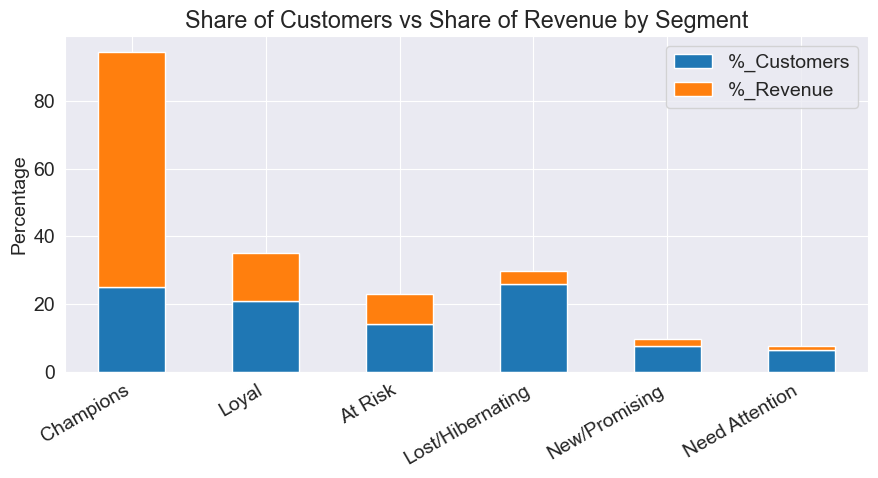

In [27]:
s = summary.sort_values('%_Revenue', ascending=False)
ax = s[['%_Customers', '%_Revenue']].plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], figsize=(9,5))
ax.set_title('Share of Customers vs Share of Revenue by Segment')
ax.set_xlabel('')
ax.set_ylabel('Percentage')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

rfm.to_csv('rfm_segments.csv', index=False)

Actions and Metric for the business

In [28]:

actions = pd.DataFrame({
    'Segment': [
        'Champions', 
        'Loyal', 
        'New/Promising', 
        'At Risk', 
        'Lost/Hibernating', 
        'Needs Attention'
    ],
    'Action': [
        'VIP tier early access & wholesaler account managers (No discounts)', 
        'Tiered milestone loyalty program to step them up', 
        'Automated onboarding sequence highlighting top sellers', 
        'Personalized category email + time-limited incentive vs control group', 
        'Cheap 2-step automated win-back sequence then list removal', 
        'Proactive feedback survey + soft reminder offer'
    ],
    'Metric': [
        'Retention rate & Average Order Value', 
        'Migration rate into Champions', 
        'Second-purchase rate within 30 days', 
        '% reactivated in 60 days vs control', 
        'Win-back rate & list-cleaning savings', 
        'Survey response rate & short-term purchase lift'
    ]
})

# Display the clean DataFrame
print(actions)
   


            Segment                                             Action  \
0         Champions  VIP tier early access & wholesaler account man...   
1             Loyal   Tiered milestone loyalty program to step them up   
2     New/Promising  Automated onboarding sequence highlighting top...   
3           At Risk  Personalized category email + time-limited inc...   
4  Lost/Hibernating  Cheap 2-step automated win-back sequence then ...   
5   Needs Attention    Proactive feedback survey + soft reminder offer   

                                            Metric  
0             Retention rate & Average Order Value  
1                    Migration rate into Champions  
2              Second-purchase rate within 30 days  
3              % reactivated in 60 days vs control  
4            Win-back rate & list-cleaning savings  
5  Survey response rate & short-term purchase lift  


In [29]:
funnel_tbl = pd.DataFrame({
    'Step': ['1. View', '2. Cart', '3. Purchase'],
    'Users': [406817, 36946, 19921]
})
funnel_tbl.to_csv('funnel.csv', index=False)

cat.reset_index().to_csv('category_funnel.csv', index=False)
rfm.to_csv('rfm_segments.csv', index=False)
summary.reset_index().to_csv('segment_summary.csv', index=False)
actions.to_csv('recommendations.csv', index=False)